In [4]:
my_data = {'CGCGGGATGGAGCAGTCTGGTAGC', 'CGCGGGATGGAGCAGTCTGGTAGCT','CGCGGGATGGAGCAGTCTGGTAGCTC',
                    'CGCGGGATGGAGCAGTCTGGTAGCTCG','CGCGGGATGGAGCAGTCTGGTAGCTCGT','CGCGGGATGGAGCAGTCTGGTAGCTCGTC','CGCGGGATGGAGCAGTCTGGTAGCTCGTCG',
                    'CGCGGGATGGAGCAGTCTGGTAGCTCGTCGG','CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGG','CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGC','CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT',
                    'CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTC','CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCA','CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCAT',
                    'CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATA','CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAA','CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAAC'}
paper_data = {'CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT','CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTC','CGCGGGATGGAGCAGTCTGGTAGCTCGTCG','CGCGGGATGGAGCAGTCTGGTAGC','CGCGGGATGGAGCAGTCTGGTAGCTCGTCGG',
              'CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAACCCGAA','CGCGGGATGGAGCAGTCTGGTAGCTCGTC','CGCGGGATGGAGCAGTCTGGTAGCT','CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGC','CGCGGGATGGAGCAGTCTGGTAGCTCGT',
              'CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCC','CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAAC', 'CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGG',
              'CGCGGGATGGAGCAGTCTGGTAGCTCG','CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCA'}

/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/matplotlib_venn/_util.py:32: UserWarning: venn2_unweighted is deprecated. Use venn2 with the appropriate layout_algorithm instead.
  warnings.warn(


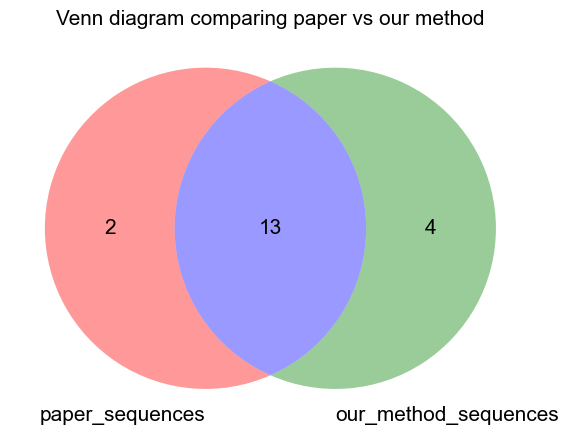

In [6]:
import matplotlib.pyplot as plt
# from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=15)

arial_font_in = fm.FontProperties(fname="arial.ttf", size=17)
plt.figure(figsize=(6, 6))
venn = venn2_unweighted([paper_data, my_data]
, set_labels=('paper_sequences', 'our_method_sequences'))
for label in venn.set_labels:
    label.set_fontproperties(arial_font)


for label in venn.subset_labels:
    if label:  # some can be None
        label.set_fontproperties(arial_font)
#plt.title("Venn diagram comparing miRDeep2 sequences vs our method-detected sequences",fontproperties=arial_font_in)
plt.xticks(fontproperties=arial_font)
plt.yticks(fontproperties=arial_font)
plt.tight_layout()
venn.get_patch_by_id('10').set_facecolor("red")
venn.get_patch_by_id('01').set_facecolor("green")
venn.get_patch_by_id('11').set_facecolor("blue")
plt.title("Venn diagram comparing paper vs our method",fontproperties=arial_font)
# plt.show()
plt.savefig("figure8_E.pdf", format="pdf", bbox_inches="tight")

In [102]:
my_data - paper_data

{'CGCGGGATGGAGCAGTCTGGTAGCTC',
 'CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCAT',
 'CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATA',
 'CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAA'}

aaa


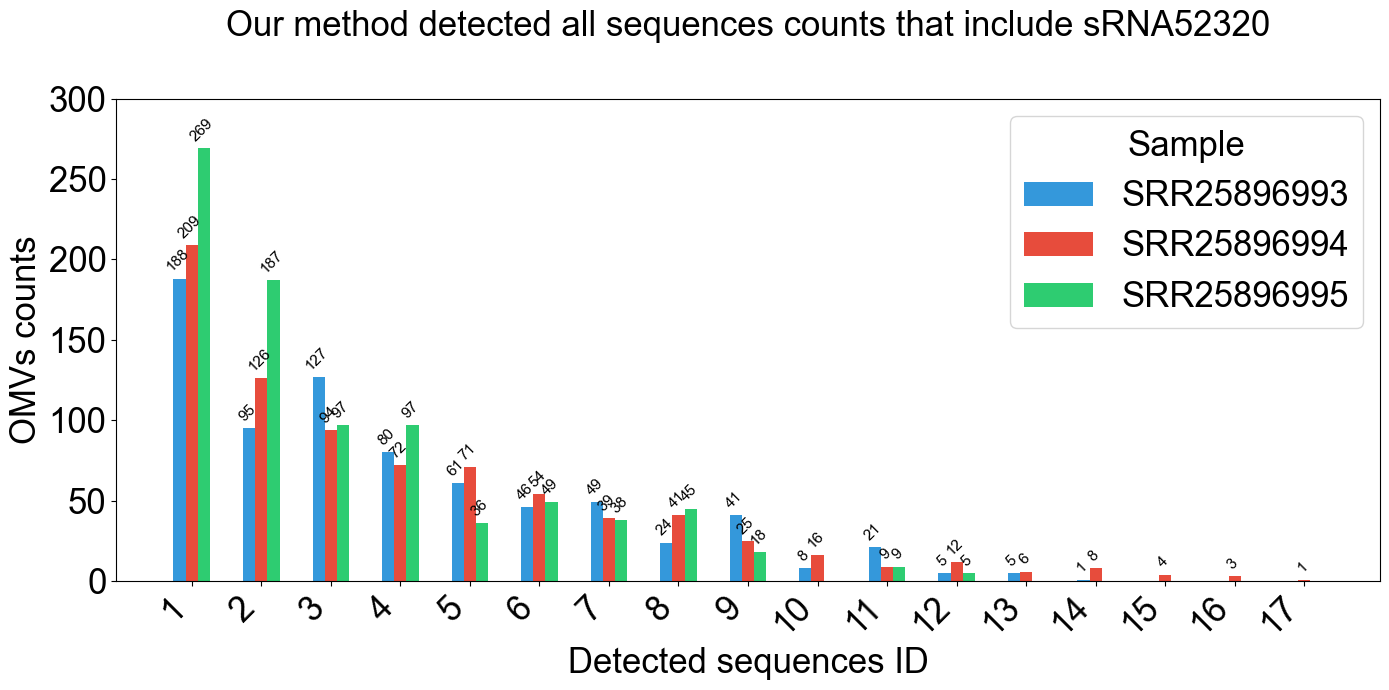

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=25)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=11)
print("aaa")
# Labels (tags)
labels = [
    "1", "2", "3", "4", "5",
    "6", "7", "8", "9","10",
    "11", "12", "13","14","15",
    "16", "17"
]


sample_a = [188, 95,  127, 80, 61,
             46, 49, 24, 41,
             8, 21, 5, 5, 1, 0, 0, 0]
sample_b = [209, 126, 94, 72, 71,
             54, 39, 41, 25,
             16, 9, 12, 6, 8, 4, 3, 1]
sample_c = [269, 187, 97, 97, 36,
            49, 38, 45, 18,
             0, 9, 5, 0, 0, 0, 0, 0]


x = np.arange(len(labels))
width = 0.35  # width of the bars

# Create plotcolor_list = [ "#3498db", "#e74c3c","#2ecc71"]
fig, ax = plt.subplots(figsize=(14, 7))
bars1 = ax.bar(x - width/2, sample_a, width/2, label='SRR25896993', color='#3498db')
bars2 = ax.bar(x , sample_b, width/2, label='SRR25896994', color='#e74c3c')
bars3 = ax.bar(x + width/2, sample_c, width/2, label='SRR25896995', color='#2ecc71')



for bar in bars1 + bars2 + bars3:
    height = bar.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    xy=(bar.get_x() + bar.get_width() / 3, height),
                    xytext=(0, 3),
                    textcoords="offset points",rotation=45,
                    ha='center', va='bottom',fontproperties=arial_font_in)

ax.set_xlabel('Detected sequences ID',fontproperties=arial_font)
ax.set_ylabel('OMVs counts',fontproperties=arial_font)
ax.set_title('Our method detected all sequences counts that include sRNA52320',fontproperties=arial_font,pad=45)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha='right',fontproperties=arial_font)
ax.set_ylim(0, 300)
ax.legend()

plt.xticks(fontproperties=arial_font)
plt.yticks(fontproperties=arial_font)
plt.tight_layout()
# plt.grid(True)
# plt.grid(True, color="lightgray", linewidth=0.1)
ax.legend(prop=arial_font, title="Sample", title_fontproperties=arial_font)
# plt.show()
plt.savefig("figure8_F.pdf", format="pdf", bbox_inches="tight")



aaa


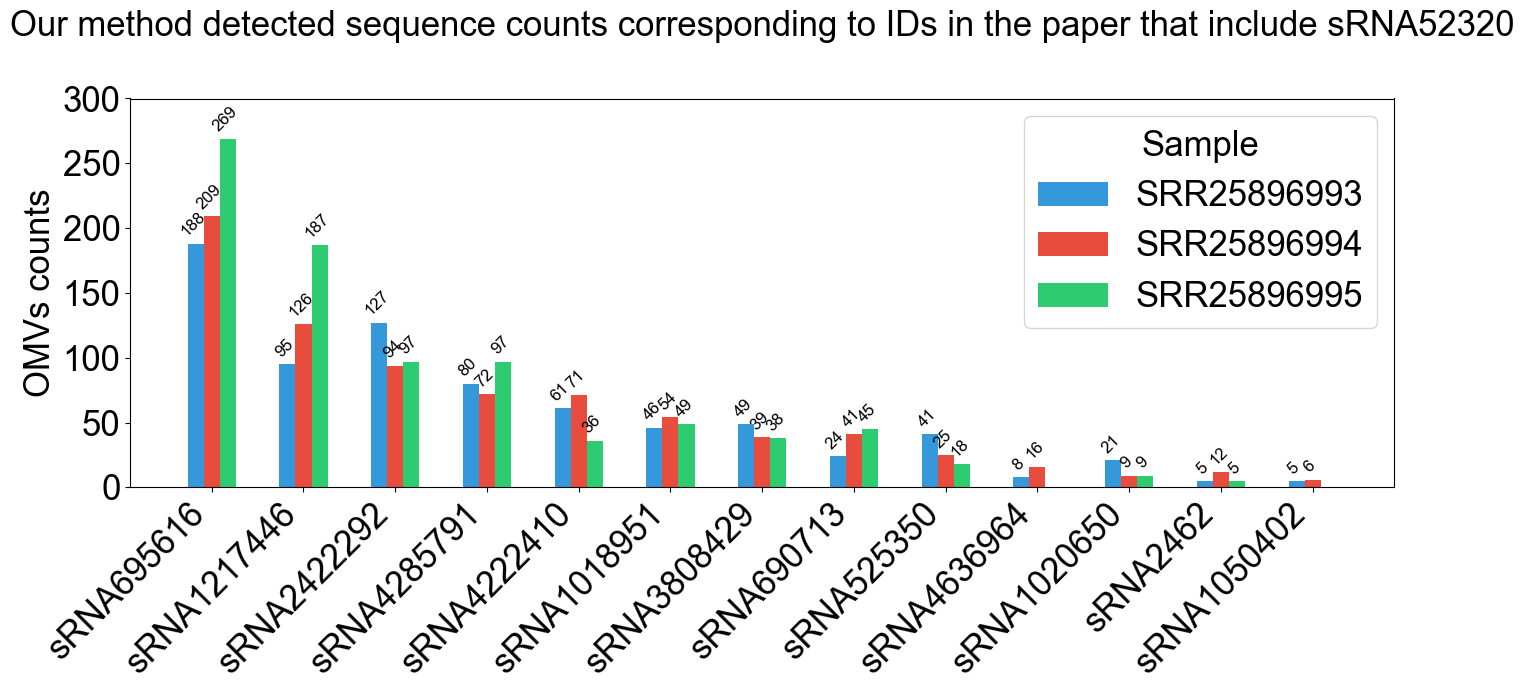

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=25)

arial_font_in = fm.FontProperties(fname="arial.ttf", size=12)
print("aaa")
# Labels (tags)
labels = [
    "sRNA695616", "sRNA1217446", "sRNA2422292", "sRNA4285791", "sRNA4222410",
     "sRNA1018951", "sRNA3808429", "sRNA690713", "sRNA525350",
    "sRNA4636964", "sRNA1020650", "sRNA2462", "sRNA1050402"
]

sample_a = [188, 95,  127, 80, 61,
             46, 49, 24, 41,
             8, 21, 5, 5]
sample_b = [209, 126, 94, 72, 71,
             54, 39, 41, 25,
            16, 9, 12, 6]
sample_c = [269, 187, 97, 97, 36,
            49, 38, 45, 18,
          0, 9, 5, 0]

x = np.arange(len(labels))
width = 0.35  # width of the bars

# Create plotcolor_list = [ "#3498db", "#e74c3c","#2ecc71"]
fig, ax = plt.subplots(figsize=(14, 7))
bars1 = ax.bar(x - width/2, sample_a, width/2, label='SRR25896993', color='#3498db')
bars2 = ax.bar(x , sample_b, width/2, label='SRR25896994', color='#e74c3c')
bars3 = ax.bar(x + width/2, sample_c, width/2, label='SRR25896995', color='#2ecc71')


for bar in bars1 + bars2 + bars3:
    height = bar.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    xy=(bar.get_x() + bar.get_width() / 3, height),
                    xytext=(0, 3),
                    textcoords="offset points",rotation=45,
                    ha='center', va='bottom',fontproperties=arial_font_in)

ax.set_ylabel('OMVs counts',fontproperties=arial_font)

ax.set_title('Our method detected sequence counts corresponding to IDs in the paper that include sRNA52320',fontproperties=arial_font,pad=45)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha='right',fontproperties=arial_font)
ax.set_ylim(0, 300)
ax.legend()

plt.xticks(fontproperties=arial_font)
plt.yticks(fontproperties=arial_font)
plt.tight_layout()
# plt.grid(True)
# plt.grid(True, color="lightgray", linewidth=0.1)
ax.legend(prop=arial_font, title="Sample", title_fontproperties=arial_font)
# plt.show()
plt.savefig("figure8_D.pdf", format="pdf", bbox_inches="tight")



In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
from Bio import SeqIO
import os

In [112]:
df = pd.read_csv("93.csv", sep='\t',header=None)
# print(name)
# print(df)
print(df[df[3] == "CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAA"])

Empty DataFrame
Columns: [0, 1, 2, 3, 4, 5, 6]
Index: []


In [113]:
df = pd.read_csv("94.csv", sep='\t',header=None)
# print(name)
# print(df)
# print(df[df[2] == 1007803])
print(df[df[3] == "CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAA"])

             0        1        2                                        3  \
3  NC_002516.2  1007765  1007803  CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAA   

         4        5  6  
3  8789113  8789113  1  


In [114]:
df = pd.read_csv("95.csv", sep='\t',header=None)
# print(name)
# print(df)
# print(df[df[2] == 1007803])
print(df[df[3] == "CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAA"])

Empty DataFrame
Columns: [0, 1, 2, 3, 4, 5, 6]
Index: []


In [7]:
df = pd.read_csv("93.csv", sep='\t',header=None)
# print(name)
# print(df)
print(df.iloc[:, [1, 2,-1]])
dataset_93 = df.iloc[:, [1, 2,-1]].values.tolist()

          1        2   6
0   1007764  1007803   8
1   1007764  1007790   2
2   1007764  1007783   2
3   1007764  1007800   3
4   1007764  1007781   1
..      ...      ...  ..
64  1007780  1007803  80
65  1007780  1007797   4
66  1007780  1007802   9
67  1007781  1007803   1
68  1007781  1007802  10

[69 rows x 3 columns]


In [8]:
df = pd.read_csv("94.csv", sep='\t',header=None)
# print(name)
# print(df)
print(df.iloc[:, [1, 2,-1]])
dataset_94 = df.iloc[:, [1, 2,-1]].values.tolist()

          1        2   6
0   1007764  1007803  16
1   1007764  1007781   1
2   1007764  1007790   7
3   1007765  1007803   1
4   1007765  1007785   1
..      ...      ...  ..
63  1007780  1007803  72
64  1007780  1007797   5
65  1007780  1007802   6
66  1007781  1007803   8
67  1007781  1007802   1

[68 rows x 3 columns]


In [9]:
df = pd.read_csv("95.csv", sep='\t',header=None)
# print(name)
# print(df)
print(df.iloc[:, [1, 2,-1]])
dataset_95 = df.iloc[:, [1, 2,-1]].values.tolist()

          1        2    6
0   1007769  1007788    6
1   1007769  1007800    2
2   1007769  1007803  187
3   1007769  1007789    8
4   1007769  1007796    2
..      ...      ...  ...
67  1007786  1007810    2
68  1007786  1007804    1
69  1007786  1007803   22
70  1007787  1007810    7
71  1007787  1007808    6

[72 rows x 3 columns]


In [20]:
import matplotlib.pyplot as plt
from PIL import Image
from brokenaxes import BrokenAxes
from intervaltree import Interval, IntervalTree
import numpy as np
import os
import random
import matplotlib.cm as cm
import argparse
import pandas as pd
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=25)

arial_font_in = fm.FontProperties(fname="arial.ttf", size=15)

def merge_intervals(intervals):
    """Merge overlapping x-axis intervals using IntervalTree."""
    tree = IntervalTree(Interval(start, end) for start, end in intervals)
    #merge overlapping intervals
    tree.merge_overlaps() 
    #return list (not tuple) 
    return sorted((iv.begin, iv.end) for iv in tree)

# function to plot each dataset
def plot_dataset(block, dataset_idx, output_folder):

    fig = plt.figure(figsize=(12, 4))
    x_min = min(int(item[0]) for item in block)
    x_max = max(int(item[1]) for item in block)
    parameter = 1

    important_ranges = []
    important_ranges = [(start, end) for start, end, _ in block]
    merged_xlims = merge_intervals(important_ranges)
    print(merged_xlims)
    distance = 0
    for start, end, line_count in block:
        if merged_xlims and int(start) == merged_xlims[0][0]:
            # logging.info("start")
            # logging.info(start)
            distance = 0
            merged_xlims.pop(0)
        y_positions = [distance + parameter * (i + 1) for i in range(int(line_count))]
        # print(y_positions)
        # random_color = np.random.rand(3,)[ "#3498db", "#e74c3c","#2ecc71"]
        for y in y_positions:
            plt.hlines(y, start, end, colors="#2ecc71", linestyles='solid', linewidth=1)
        distance = y_positions[-1]
    
    plt.xticks(np.arange(1007769, 1007811, 1), rotation=45)
    #ymax=1018
    # ymax = 1068
    ymax = 1221
    plt.ylim(0, ymax * 1.05)                        
    yticks = plt.yticks()[0]
    if ymax not in yticks:
        plt.yticks(list(yticks) + [ymax])   
    #save the plot to a buffer as a grayscale image
    plt.tight_layout()
    plt.xlabel('Mapping sequences to the reference genome (genomic axis)',fontproperties=arial_font)
    plt.ylabel('sequences counts',fontproperties=arial_font)
    plt.title('Our method found block in Sample SRR25896995 ',fontproperties=arial_font,pad=45)
    plt.xticks(fontproperties=arial_font_in)
    plt.yticks(fontproperties=arial_font_in)
    # plt.show()
    plt.savefig("figure8_block_95.pdf", format="pdf", bbox_inches="tight")

          1        2   6
0   1007764  1007803   8
1   1007764  1007790   2
2   1007764  1007783   2
3   1007764  1007800   3
4   1007764  1007781   1
..      ...      ...  ..
64  1007780  1007803  80
65  1007780  1007797   4
66  1007780  1007802   9
67  1007781  1007803   1
68  1007781  1007802  10

[69 rows x 3 columns]
1018
[(1007764, 1007805)]


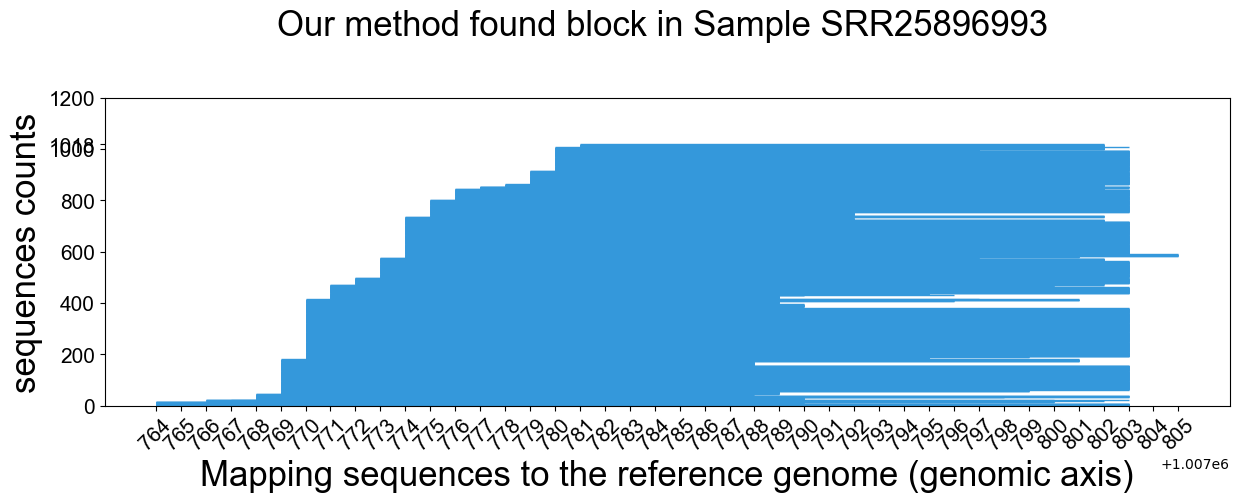

In [11]:
# dataset = [ [4,21,1],[62,80,44],[63,80,59],[100,114,1], 
#             [230,249,1],[232,252,1],[232,253,2],[232,254,4],[282,299,8],[318,341,7],
#             [345,376,16],[381,405,17],[402,420,15],[418,430,20],
#             [500,538,3],[518,557,2],[615,635,2],[643,660,1],
#             [675,694,24],[675,692,1],[676,693,78],[676,694,95],[676,693,1],[761,779,2],
#             [866,886,16],[876,904,13],[887,904,1],[923,951,19],[1010,1046,5]
#          ]
df = pd.read_csv("93.csv", sep='\t',header=None)
# print(name)
# print(df)
print(df.iloc[:, [1, 2,-1]])
print(df.iloc[:, -1].sum())
dataset_93 = df.iloc[:, [1, 2,-1]].values.tolist()
plot_dataset(dataset_93, 0, "simulation_data")

          1        2   6
0   1007764  1007803  16
1   1007764  1007781   1
2   1007764  1007790   7
3   1007765  1007803   1
4   1007765  1007785   1
..      ...      ...  ..
63  1007780  1007803  72
64  1007780  1007797   5
65  1007780  1007802   6
66  1007781  1007803   8
67  1007781  1007802   1

[68 rows x 3 columns]
1068
[(1007764, 1007810)]


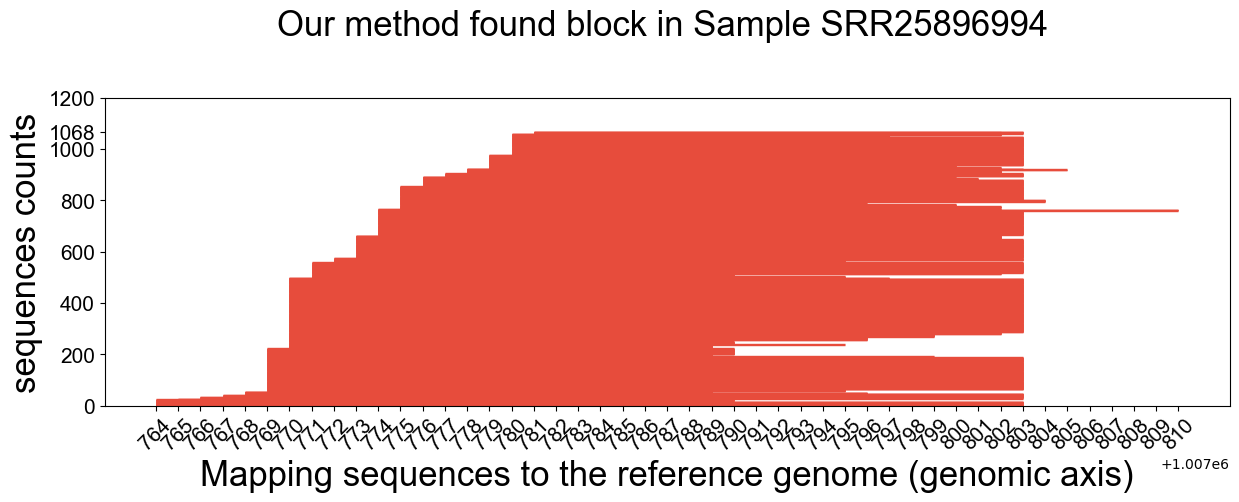

In [16]:
df = pd.read_csv("94.csv", sep='\t',header=None)
# print(name)
# print(df)
print(df.iloc[:, [1, 2,-1]])
print(df.iloc[:, -1].sum())
dataset_94 = df.iloc[:, [1, 2,-1]].values.tolist()
plot_dataset(dataset_94, 0, "simulation_data")

1221
          1        2    6
0   1007769  1007788    6
1   1007769  1007800    2
2   1007769  1007803  187
3   1007769  1007789    8
4   1007769  1007796    2
..      ...      ...  ...
67  1007786  1007810    2
68  1007786  1007804    1
69  1007786  1007803   22
70  1007787  1007810    7
71  1007787  1007808    6

[72 rows x 3 columns]
[(1007769, 1007810)]


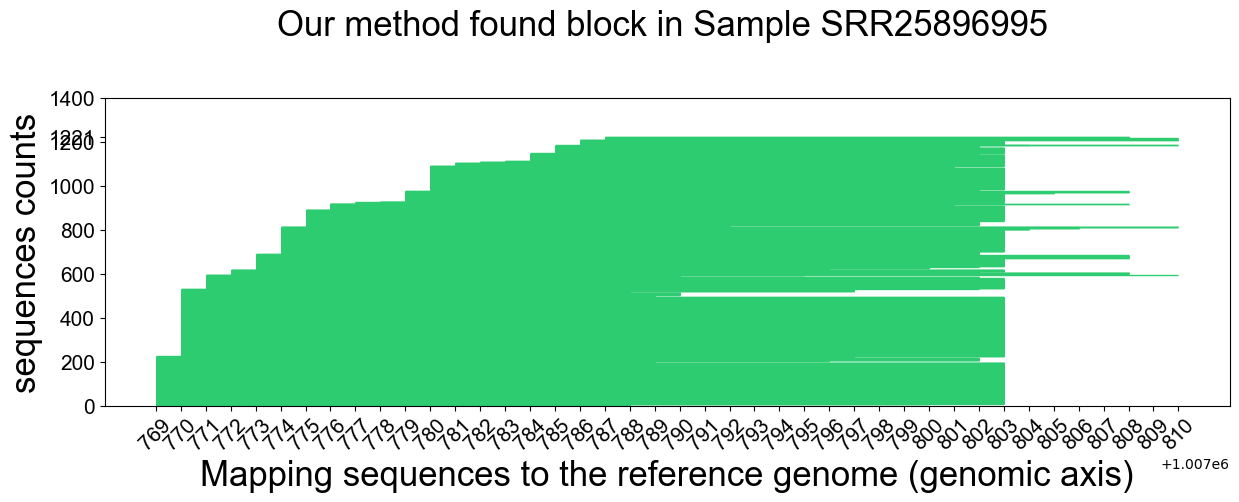

In [21]:
df = pd.read_csv("95.csv", sep='\t',header=None)
# print(name)
# print(df)
print(df.iloc[:, -1].sum())
print(df.iloc[:, [1, 2,-1]])
dataset_95 = df.iloc[:, [1, 2,-1]].values.tolist()
plot_dataset(dataset_95, 0, "simulation_data")